# 📰 FlipItNews – Automated News Categorization

**Goal:** read a news article → predict its category (business, sport, politics, tech, entertainment).

**Steps in this notebook**
1. Import libraries
2. Load the data
3. Exploratory Data Analysis (EDA)
4. Text preprocessing
5. Train / test split
6. Feature extraction: Bag of Words, TF-IDF, Word2Vec
7. Neural Network (NN) models
8. Recurrent Neural Network (RNN) models
9. Compare all models
10. Business impact
11. Save the RNN and build the web dashboard

> Run the cells from top to bottom. Keep `bbc-news-data.csv` in the same folder as this notebook.

## Step 1 – Import libraries

In [1]:
# If a library is missing, uncomment and run this line once:
# !pip install pandas numpy matplotlib seaborn scikit-learn nltk gensim tensorflow streamlit

import re, json, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

from gensim.models import Word2Vec

import tensorflow as tf
from tensorflow.keras import layers, models

# Fix the random seeds so results are (almost) repeatable
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
print("Libraries imported. TensorFlow version:", tf.__version__)

I0000 00:00:1791993230.586994     823 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791993230.996100     823 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791993233.375377     823 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Libraries imported. TensorFlow version: 2.21.0


## Step 2 – Load the data

⚠️ Although the file ends with `.csv`, the columns are separated by **tabs**, not commas.
So we must use `sep='\t'`.

In [2]:
df = pd.read_csv("bbc-news-data.csv", sep="\t")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2225, 4)


,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


## Step 3 – Exploratory Data Analysis (EDA)

### 3.1 Basic information and missing values

In [3]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate articles (same content):", df["content"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  2225 non-null   str  
 1   filename  2225 non-null   str  
 2   title     2225 non-null   str  
 3   content   2225 non-null   str  
dtypes: str(4)
memory usage: 4.9 MB

Missing values per column:
category    0
filename    0
title       0
content     0
dtype: int64

Duplicate articles (same content): 133


**What we learn:** there are no missing values, but some articles appear more than once.
Duplicates are dangerous: the same article could land in both the train set and the test set,
which makes the score look better than it really is. We remove them.

In [4]:
df = df.drop_duplicates(subset="content").reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (2092, 4)


### 3.2 Distribution of news categories

category
business         500
sport            494
politics         395
entertainment    366
tech             337
Name: count, dtype: int64


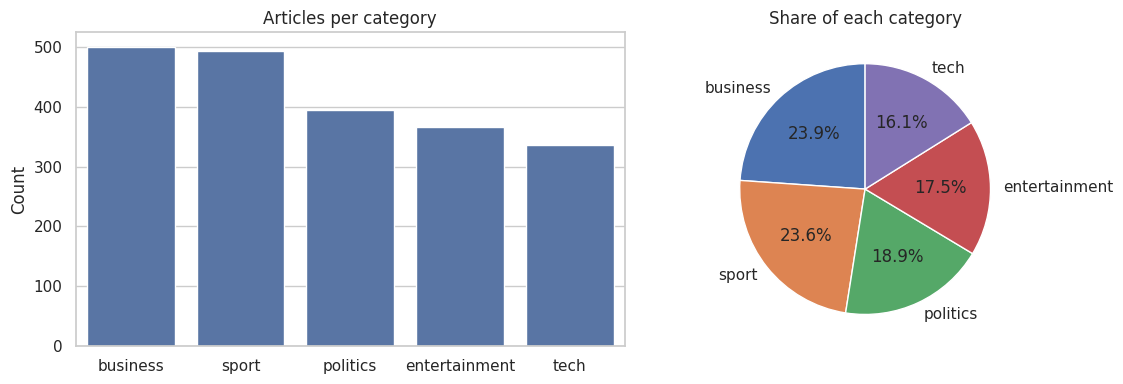

In [5]:
counts = df["category"].value_counts()
print(counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="category", order=counts.index, ax=axes[0])
axes[0].set_title("Articles per category")
axes[0].set_xlabel(""); axes[0].set_ylabel("Count")

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Share of each category")

plt.tight_layout(); plt.show()

**What we learn:** the five classes are fairly balanced (no category is tiny),
so accuracy is a reasonable metric here. We still report precision, recall and F1 as asked.

### 3.3 Article length

count    2092.0
mean      384.0
std       241.9
min        89.0
25%       244.0
50%       330.0
75%       471.0
max      4432.0
Name: word_count, dtype: float64


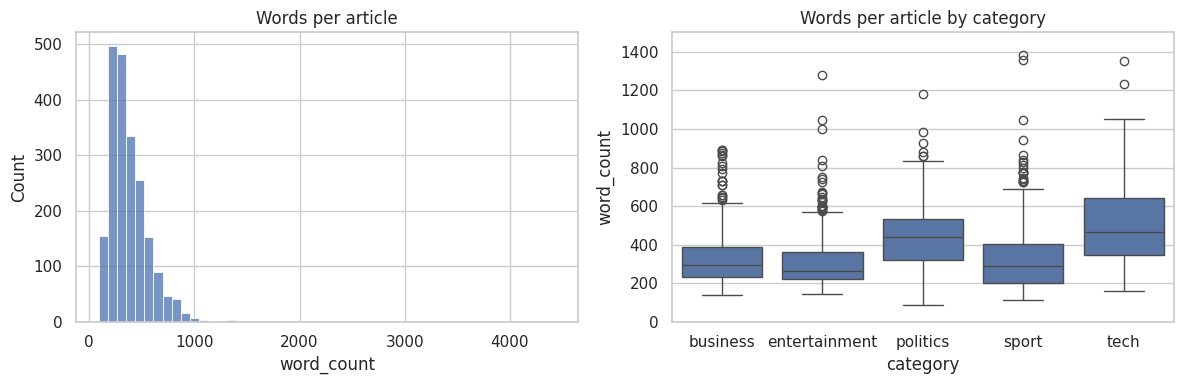

In [6]:
# Combine title + content into one text column (the title is short but very informative)
df["text"] = df["title"] + " " + df["content"]
df["word_count"] = df["text"].str.split().str.len()

print(df["word_count"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["word_count"], bins=50, ax=axes[0])
axes[0].set_title("Words per article")
sns.boxplot(data=df, x="category", y="word_count", ax=axes[1])
axes[1].set_title("Words per article by category")
axes[1].set_ylim(0, 1500)   # zoom in; a few very long articles exist
plt.tight_layout(); plt.show()

**What we learn:** most articles have 200–500 words. This helps us choose a sensible maximum length for the RNN later.

## Step 4 – Text preprocessing

For every article we will:
1. convert to **lowercase**
2. remove **punctuation** (and numbers)
3. **tokenize** (split into words)
4. remove **stop words** (very common words like *the, is, and* that carry little meaning)

In [7]:
nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()                            # 1. lowercase
    text = re.sub(r"[^a-z\s]", " ", text)          # 2. keep only letters and spaces
    tokens = text.split()                          # 3. tokenization -> list of words
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]  # 4. remove stop words
    return tokens

# Quick demo
example = "The Prime Minister said, \"We will fight!\" on Friday."
print("Before:", example)
print("After :", clean_text(example))

Before: The Prime Minister said, "We will fight!" on Friday.
After : ['prime', 'minister', 'said', 'fight', 'friday']


In [8]:
df["tokens"]     = df["text"].apply(clean_text)       # list of words
df["clean_text"] = df["tokens"].apply(" ".join)       # same words as one string

df[["category", "clean_text"]].head()

,category,clean_text
0,business,ad sales boost time warner profit quarterly pr...
1,business,dollar gains greenspan speech dollar hit highe...
2,business,yukos unit buyer faces loan claim owners embat...
3,business,high fuel prices hit ba profits british airway...
4,business,pernod takeover talk lifts domecq shares uk dr...


## Step 5 – Train / test split

Computers need numbers, so first we turn category names into numbers (0–4).
Then we keep **80 % for training** and **20 % for testing**.
`stratify` keeps the same category proportions in both parts.
All models below use exactly the same split, so the comparison is fair.

In [9]:
le = LabelEncoder()
y = le.fit_transform(df["category"])
class_names = list(le.classes_)
print("Classes:", dict(zip(class_names, range(len(class_names)))))

train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2,
                                       stratify=y, random_state=SEED)

train_text   = df["clean_text"].iloc[train_idx]
test_text    = df["clean_text"].iloc[test_idx]
train_tokens = df["tokens"].iloc[train_idx].tolist()
test_tokens  = df["tokens"].iloc[test_idx].tolist()
y_train, y_test = y[train_idx], y[test_idx]

print("Train articles:", len(train_idx), "| Test articles:", len(test_idx))

Classes: {'business': 0, 'entertainment': 1, 'politics': 2, 'sport': 3, 'tech': 4}
Train articles: 1673 | Test articles: 419


## Step 6 – Feature extraction (text → numbers)

| Method | Idea |
|---|---|
| **Bag of Words (BoW)** | Count how many times each word appears. Word order is ignored. |
| **TF-IDF** | Like BoW, but gives *rare, meaningful* words more weight than words that appear everywhere. |
| **Word2Vec** | Each word becomes a vector of 100 numbers; similar words get similar vectors. An article = the average of its word vectors. |

We always **fit on the training data only** and then transform the test data (so the test set stays unseen).

In [10]:
# ---- Bag of Words ----
bow = CountVectorizer(max_features=5000)            # keep the 5000 most frequent words
X_train_bow = bow.fit_transform(train_text).toarray()
X_test_bow  = bow.transform(test_text).toarray()

# ---- TF-IDF ----
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(train_text).toarray()
X_test_tfidf  = tfidf.transform(test_text).toarray()

print("BoW    shape:", X_train_bow.shape)
print("TF-IDF shape:", X_train_tfidf.shape)

BoW    shape: (1673, 5000)
TF-IDF shape: (1673, 5000)


In [11]:
# ---- Word2Vec ----
# Train Word2Vec on the training articles (each article = list of words)
w2v = Word2Vec(sentences=train_tokens, vector_size=100, window=5,
               min_count=2, epochs=20, seed=SEED, workers=1)

# Check what it learned (only ~1,700 articles, so some neighbours are noisy)
print("Words similar to 'football':", [w for w, _ in w2v.wv.most_similar("football", topn=5)])

def article_to_vector(tokens):
    # average the vectors of all known words in the article
    vectors = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(100)

X_train_w2v = np.array([article_to_vector(t) for t in train_tokens])
X_test_w2v  = np.array([article_to_vector(t) for t in test_tokens])
print("Word2Vec shape:", X_train_w2v.shape)

Words similar to 'football': ['rugby', 'manager', 'sculthorpe', 'cruel', 'gravesen']


Word2Vec shape: (1673, 100)


## Step 7 – Neural Network (NN) models

A simple feed-forward network: `Dense(128) → Dropout → Dense(64) → Dense(5, softmax)`.
* **Dropout** randomly switches off neurons while training to reduce over-fitting.
* **Softmax** outputs 5 probabilities (one per category) that add up to 1.
* **EarlyStopping** stops training when the validation loss stops improving.

We train the *same* network on each of the three feature types.

In [12]:
results = []   # we will store every model's scores here

def evaluate(name, y_true, y_pred):
    # 'weighted' averages the per-class scores, taking class size into account
    results.append({
        "Model":     name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted"),
        "Recall":    recall_score(y_true, y_pred, average="weighted"),
        "F1-score":  f1_score(y_true, y_pred, average="weighted"),
    })

def build_nn(input_dim, n_classes=5):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train_and_evaluate(name, model, X_tr, y_tr, X_te, y_te, epochs=30):
    early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                  restore_best_weights=True)
    history = model.fit(X_tr, y_tr, validation_split=0.1, epochs=epochs,
                        batch_size=32, callbacks=[early_stop], verbose=0)
    y_pred = np.argmax(model.predict(X_te, verbose=0), axis=1)
    evaluate(name, y_te, y_pred)
    print(f"{name}: trained {len(history.history['loss'])} epochs, "
          f"test accuracy = {accuracy_score(y_te, y_pred):.4f}")
    return history, y_pred

In [13]:
nn_bow   = build_nn(X_train_bow.shape[1])
h1, p1   = train_and_evaluate("NN + BoW",      nn_bow,   X_train_bow,   y_train, X_test_bow,   y_test)

nn_tfidf = build_nn(X_train_tfidf.shape[1])
h2, p2   = train_and_evaluate("NN + TF-IDF",   nn_tfidf, X_train_tfidf, y_train, X_test_tfidf, y_test)

nn_w2v   = build_nn(X_train_w2v.shape[1])
h3, p3   = train_and_evaluate("NN + Word2Vec", nn_w2v,   X_train_w2v,   y_train, X_test_w2v,   y_test)

NN + BoW: trained 11 epochs, test accuracy = 0.9714


NN + TF-IDF: trained 12 epochs, test accuracy = 0.9785


NN + Word2Vec: trained 19 epochs, test accuracy = 0.9666


## Step 8 – Recurrent Neural Network (RNN)

An RNN reads the article **word by word, in order**, so it can use word order and context
(the NN above only saw a "bag" of words). We use an **LSTM**, a popular type of RNN.

**How we feed text to an RNN**
1. Build a vocabulary: each word → an integer id (`0` = padding, `1` = unknown word).
2. Convert every article into a list of ids.
3. Cut / pad every article to the same length (`MAX_LEN` words).
4. An **Embedding** layer turns each id into a vector, then the LSTM reads the sequence.

We try two versions:
* **RNN (own embedding)** – the embedding is learned while training.
* **RNN + Word2Vec** – the embedding starts from our Word2Vec vectors (kept fixed).

In [14]:
MAX_WORDS = 10000    # vocabulary size
MAX_LEN   = 200      # words kept per article (most articles are 200-500 words)

# 1. Vocabulary from the TRAINING articles only
word_counts = Counter(w for tokens in train_tokens for w in tokens)
vocab = {w: i + 2 for i, (w, _) in enumerate(word_counts.most_common(MAX_WORDS - 2))}

# 2 + 3. words -> ids, then cut / pad to MAX_LEN
def to_padded(token_lists):
    seqs = [[vocab.get(w, 1) for w in tokens] for tokens in token_lists]
    return tf.keras.utils.pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train_seq = to_padded(train_tokens)
X_test_seq  = to_padded(test_tokens)

print("Vocabulary size:", len(vocab) + 2)
print("Sequence shape :", X_train_seq.shape)
print("First article as ids:", X_train_seq[0][:15], "...")

Vocabulary size: 10000
Sequence shape : (1673, 200)
First article as ids: [2586 7111    1 1057 5157 2586  700  294 2069  138  592  141  144 5979
  207] ...


In [15]:
# Embedding matrix for the Word2Vec version: row i = vector of the word with id i
embedding_matrix = np.zeros((len(vocab) + 2, 100))
for word, idx in vocab.items():
    if word in w2v.wv:
        embedding_matrix[idx] = w2v.wv[word]

def build_rnn(use_word2vec=False, n_classes=5):
    if use_word2vec:
        embedding = layers.Embedding(len(vocab) + 2, 100, weights=[embedding_matrix],
                                     trainable=False, mask_zero=True)
    else:
        embedding = layers.Embedding(len(vocab) + 2, 100, mask_zero=True)

    model = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        embedding,                                   # ids -> vectors
        layers.Bidirectional(layers.LSTM(64)),       # read the text forwards and backwards
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

rnn_own = build_rnn(use_word2vec=False)
rnn_own.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,085,125 (4.14 MB)

 Trainable params: 1,085,125 (4.14 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
h4, p4 = train_and_evaluate("RNN (own embedding)", rnn_own, X_train_seq, y_train, X_test_seq, y_test, epochs=20)

rnn_w2v = build_rnn(use_word2vec=True)
h5, p5 = train_and_evaluate("RNN + Word2Vec", rnn_w2v, X_train_seq, y_train, X_test_seq, y_test, epochs=30)

E0000 00:00:1791993303.701099     823 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


RNN (own embedding): trained 10 epochs, test accuracy = 0.9499


RNN + Word2Vec: trained 22 epochs, test accuracy = 0.9594


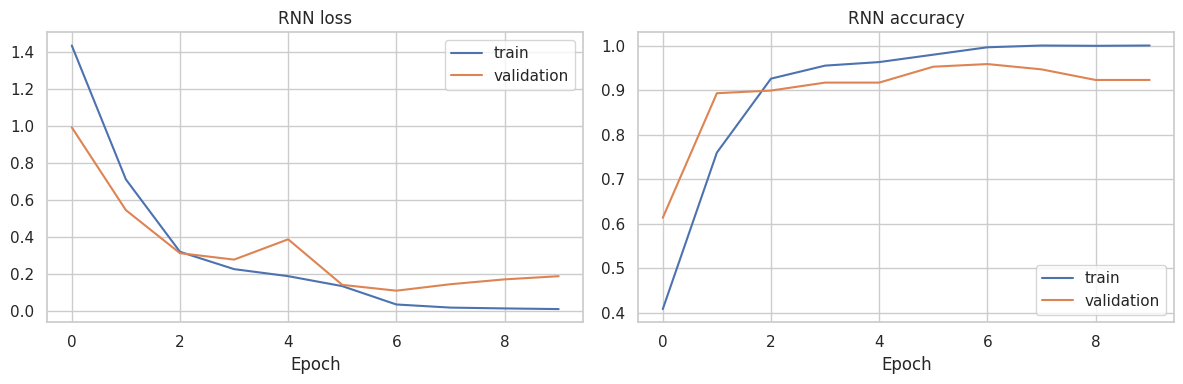

In [17]:
# Training curves of the RNN (own embedding)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h4.history["loss"], label="train"); axes[0].plot(h4.history["val_loss"], label="validation")
axes[0].set_title("RNN loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h4.history["accuracy"], label="train"); axes[1].plot(h4.history["val_accuracy"], label="validation")
axes[1].set_title("RNN accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## Step 9 – Compare all models

* **Accuracy** – % of articles classified correctly.
* **Precision** – when the model says "sport", how often is it right?
* **Recall** – of all real "sport" articles, how many did the model find?
* **F1-score** – balance of precision and recall.

(Precision, recall and F1 are averaged over the 5 classes, weighted by class size.)

In [18]:
results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,NN + TF-IDF,0.9785,0.9790,0.9785,0.9786
1,NN + BoW,0.9714,0.9719,0.9714,0.9715
2,NN + Word2Vec,0.9666,0.9675,0.9666,0.9668
3,RNN + Word2Vec,0.9594,0.9612,0.9594,0.9596
4,RNN (own embedding),0.9499,0.9509,0.9499,0.9498


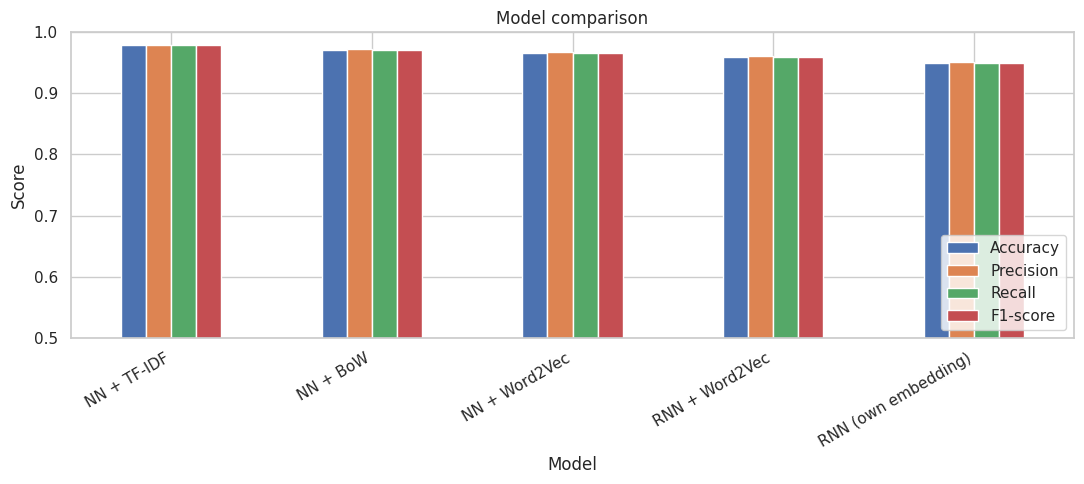

In [19]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0.5, 1.0))
plt.title("Model comparison"); plt.ylabel("Score"); plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

Best RNN: RNN + Word2Vec 

               precision    recall  f1-score   support

     business      0.989     0.920     0.953       100
entertainment      0.934     0.973     0.953        73
     politics      0.907     0.987     0.945        79
        sport      0.990     0.970     0.980        99
         tech      0.970     0.956     0.963        68

     accuracy                          0.959       419
    macro avg      0.958     0.961     0.959       419
 weighted avg      0.961     0.959     0.960       419



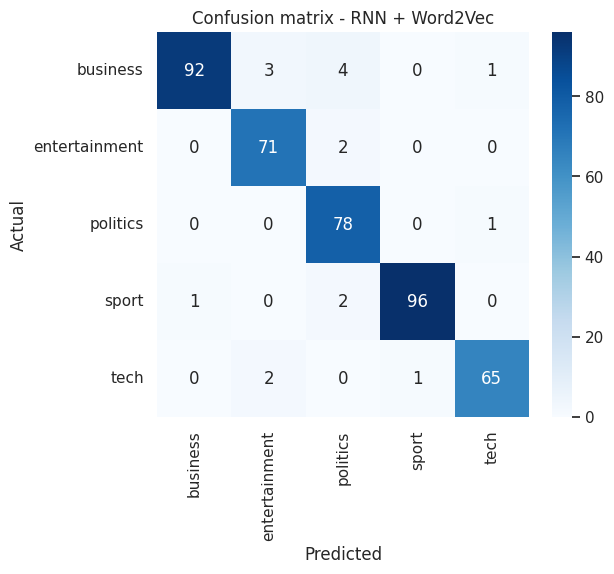

In [20]:
# Look closer at the RNN versions: per-class report + confusion matrix
rnn_preds = {"RNN (own embedding)": p4, "RNN + Word2Vec": p5}
best_rnn_name = max(rnn_preds, key=lambda n: f1_score(y_test, rnn_preds[n], average="weighted"))
best_rnn_pred = rnn_preds[best_rnn_name]
best_rnn_model = rnn_own if best_rnn_name == "RNN (own embedding)" else rnn_w2v
print("Best RNN:", best_rnn_name, "\n")

print(classification_report(y_test, best_rnn_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_test, best_rnn_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix - {best_rnn_name}")
plt.show()

In [21]:
# Which articles does the best RNN get wrong?
wrong = np.where(best_rnn_pred != y_test)[0]
print(f"{len(wrong)} wrong predictions out of {len(y_test)}\n")
for i in wrong[:5]:
    print("Actual:", class_names[y_test[i]], "| Predicted:", class_names[best_rnn_pred[i]])
    print("   ", df["title"].iloc[test_idx[i]])

17 wrong predictions out of 419

Actual: politics | Predicted: tech
    UK firms 'embracing e-commerce'
Actual: sport | Predicted: politics
    Calder fears for Scottish rugby
Actual: business | Predicted: politics
    Call to overhaul UK state pension
Actual: business | Predicted: tech
    Card fraudsters 'targeting web'
Actual: business | Predicted: entertainment
    McDonald's boss Bell dies aged 44


### How to read the results
* Look at the table above: the **top row is the best model** by F1-score.
* On a small, clean dataset like this one (~2,100 articles, clear topics), simple
  **TF-IDF + NN** is often as good as or better than an RNN, because topic words alone
  (e.g. *goal, minister, shares*) are enough. RNNs shine when word order matters more
  and when there is lots of data.
* The confusion matrix shows **which categories get mixed up** (usually business ↔ politics,
  or tech ↔ business), because those topics share vocabulary.

## Step 10 – How automated categorization helps FlipItNews

**Content organization**
* Every new article is tagged in milliseconds, so editors do not label thousands of articles by hand.
* Consistent labels → clean section pages (Sport, Business, …), better internal search and filters.
* Low-confidence predictions can be sent to an editor, so humans only review the hard cases.

**Personalized news delivery**
* Track which categories each reader opens and recommend more of those.
* Let users follow categories and send push notifications / newsletters per category.
* Category + reading history gives a simple and explainable base for a recommendation system.

**Limitations to keep in mind**
* The model only knows 5 BBC-style categories (no *health*, *education*, *regional news*).
* It was trained on BBC articles from 2004-05. Indian news and new topics will need
  **fresh labelled data** and periodic retraining.
* An article about two topics (e.g. "tech company profits") can only get one label.

## Step 11 – Save the RNN and build the web dashboard

We save everything the dashboard needs:
* `rnn_model.keras` – the trained RNN
* `artifacts.json` – vocabulary, class names and `MAX_LEN` (so the app prepares text **exactly** like we did here)

In [22]:
best_rnn_model.save("rnn_model.keras")

with open("artifacts.json", "w") as f:
    json.dump({"vocab": vocab, "classes": class_names, "max_len": MAX_LEN}, f)

print("Saved: rnn_model.keras and artifacts.json  (deployed model:", best_rnn_name + ")")

Saved: rnn_model.keras and artifacts.json  (deployed model: RNN + Word2Vec)


In [23]:
# Quick test of the full pipeline: raw text -> prediction
def predict_category(text):
    ids = to_padded([clean_text(text)])
    probs = best_rnn_model.predict(ids, verbose=0)[0]
    return class_names[np.argmax(probs)], float(probs.max())

def show(text):
    label, conf = predict_category(text)
    print(f"{label} ({conf:.1%})")

show("The striker scored twice as the club won the league title on Saturday.")
show("The chancellor announced new tax rules and the central bank raised interest rates.")
show("The new smartphone has a faster processor and improved mobile software.")

sport (100.0%)


business (94.6%)
tech (99.3%)


### The dashboard (Streamlit)
The next cell writes the file `app.py`. It:
1. loads the saved RNN and settings,
2. applies the **same cleaning** as this notebook,
3. shows the predicted category, a confidence score and a probability bar chart,
4. has a **batch tab**: upload a CSV with a `text` column and download the predicted categories.

In [24]:
%%writefile app.py
# app.py  -  FlipItNews: Automated News Categorization Dashboard
# Run with:  streamlit run app.py
import json
import re

import nltk
import numpy as np
import pandas as pd
import streamlit as st
import tensorflow as tf
from nltk.corpus import stopwords

st.set_page_config(page_title="FlipItNews Classifier", page_icon="📰", layout="centered")


# ---------- 1. Load the trained model + settings (only once) ----------
@st.cache_resource
def load_everything():
    try:
        stop_words = set(stopwords.words("english"))
    except LookupError:
        nltk.download("stopwords", quiet=True)
        stop_words = set(stopwords.words("english"))
    model = tf.keras.models.load_model("rnn_model.keras")
    with open("artifacts.json") as f:
        art = json.load(f)
    return model, art, stop_words


model, art, stop_words = load_everything()
vocab, classes, MAX_LEN = art["vocab"], art["classes"], art["max_len"]


# ---------- 2. Same preprocessing as the notebook (must match!) ----------
def clean_text(text):
    text = text.lower()                                   # lowercase
    text = re.sub(r"[^a-z\s]", " ", text)                 # remove punctuation / numbers
    tokens = text.split()                                 # tokenization
    return [w for w in tokens if w not in stop_words and len(w) > 1]  # remove stop words


def predict_proba(texts):
    seqs = [[vocab.get(w, 1) for w in clean_text(t)] for t in texts]   # words -> numbers
    padded = tf.keras.utils.pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")
    return model.predict(padded, verbose=0)


# ---------- 3. Sample articles so the demo works instantly ----------
SAMPLES = {
    "-- write my own --": "",
    "Sport": "England beat Australia by five wickets in the final Test, with the captain scoring a "
             "brilliant century as the home crowd cheered. The team now leads the series and the "
             "coach praised the bowlers for a disciplined performance on the last day.",
    "Business": "Shares in the airline rose 4% after it reported higher quarterly profits and said "
                "falling fuel costs would boost revenues. Analysts expect the company to raise its "
                "full-year forecast, while the central bank held interest rates steady.",
    "Politics": "The prime minister faced questions in parliament over the new immigration bill. "
                "Opposition MPs said the government had failed to consult, and a vote is expected "
                "next week ahead of the general election.",
    "Tech": "The software firm has released a new smartphone operating system with improved "
            "security and faster mobile broadband support. Users can download the update for free, "
            "and developers say the new browser is much quicker.",
    "Entertainment": "The film won three awards at the ceremony in Los Angeles, including best "
                     "actress. The singer also performed her new album's title track, and the "
                     "director thanked the cast backstage.",
}

# ---------- 4. The web page ----------
st.title("📰 FlipItNews - Automatic News Categoriser")
st.write("Paste a news article and the trained **RNN (LSTM)** model predicts its category.")

with st.sidebar:
    st.header("About")
    st.write("Model: RNN (LSTM) trained on the BBC News dataset.")
    st.write("Categories: " + ", ".join(c.title() for c in classes))
    st.caption(f"Articles are cut/padded to {MAX_LEN} words.")

tab_single, tab_batch = st.tabs(["Single article", "Batch (CSV)"])

with tab_single:
    choice = st.selectbox("Try a sample article", list(SAMPLES.keys()))
    text = st.text_area("News text", value=SAMPLES[choice], height=200,
                        placeholder="Paste a news article here...")

    if st.button("Classify", type="primary"):
        if len(text.split()) < 10:
            st.warning("Please enter at least 10 words.")
        else:
            probs = predict_proba([text])[0]
            best = int(np.argmax(probs))
            st.success(f"Predicted category: **{classes[best].title()}**")
            st.metric("Confidence", f"{probs[best] * 100:.1f}%")
            if probs[best] < 0.6:
                st.info("Low confidence - this article may need a human editor to check it.")
            chart = pd.DataFrame({"Probability": probs}, index=[c.title() for c in classes])
            st.bar_chart(chart)

with tab_batch:
    st.write("Upload a CSV with a column named **text** to label many articles at once.")
    file = st.file_uploader("CSV file", type="csv")
    if file is not None:
        data = pd.read_csv(file)
        if "text" not in data.columns:
            st.error("The CSV must contain a 'text' column.")
        else:
            probs = predict_proba(data["text"].astype(str).tolist())
            data["predicted_category"] = [classes[i] for i in probs.argmax(axis=1)]
            data["confidence"] = probs.max(axis=1).round(3)
            st.dataframe(data)
            st.download_button("Download results", data.to_csv(index=False), "predictions.csv")

Writing app.py


In [25]:
%%writefile requirements.txt
streamlit
tensorflow-cpu
nltk
pandas
numpy

Writing requirements.txt


### Run the dashboard on your computer
Open a terminal in the folder containing `app.py`, `rnn_model.keras` and `artifacts.json`:
```
pip install -r requirements.txt
streamlit run app.py
```
It opens at `http://localhost:8501`.

### Host it online (free)
**Option A – Streamlit Community Cloud**
1. Create a GitHub repo containing: `app.py`, `requirements.txt`, `rnn_model.keras`, `artifacts.json`.
2. Go to **share.streamlit.io** → sign in with GitHub → *New app* → pick the repo and `app.py`.
3. In *Advanced settings* choose **Python 3.11 or 3.12** (TensorFlow does not support the newest Python versions) → *Deploy*.

**Option B – Hugging Face Spaces** → create a new Space with the *Streamlit* SDK and upload the same 4 files.

The model file is only a few MB, so normal GitHub upload works.